# Sunday Project: Data Quality, Insights & CSV Operations
**AI Engineering Bootcamp | Module 02**

This notebook has two parts:
- **Part A**: Data Quality & Basic Insights 
- **Part B**: CSV File Handling & Manipulation 

In [1]:
# Import the libraries we need
import pandas as pd
import matplotlib.pyplot as plt

# Part A: Data Quality & Basic Insights

## 1. Load and inspect

In [2]:
# Read the raw CSV file (relative path, works in Jupyter and Colab)
df = pd.read_csv("sales_raw.csv")

# Keep a copy of the raw data so the original stays untouched
raw_rows = df.shape[0]

# First 5 rows
print(df.head())

   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250


In [3]:
# Shape (rows, columns)
print("Shape:", df.shape)

# Column names
print("Columns:", list(df.columns))

# Data types of each column
print(df.dtypes)

Shape: (21, 6)
Columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object


In [4]:
# Missing values in each column
print(df.isna().sum())

# Number of duplicate rows
print("Duplicate rows:", df.duplicated().sum())

transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64
Duplicate rows: 1


**What we found in the raw data:**
- `region` and `category` have extra spaces and mixed case (`SOUTH`, ` food`, `books`).
- `region` has 1 missing value, `quantity` has 1 missing value, `unit_price` has 1 missing value.
- `unit_price` has a text value (`invalid`), which is why its type is object (text), not a number.
- `quantity` has a negative value (-2), which is not possible for a sale.
- `unit_price` has one unrealistic value (10000 for Stationery).
- There is 1 duplicate row (transaction 1003).

## 2. Clean the dataset

In [5]:
# Step 1: Trim extra spaces and make text consistent (Title Case)
df["region"] = df["region"].str.strip().str.title()
df["category"] = df["category"].str.strip().str.title()

# Check the unique values now
print(df["region"].unique())
print(df["category"].unique())

<StringArray>
['North', 'South', 'East', 'West', nan]
Length: 5, dtype: str
<StringArray>
['Food', 'Books', 'Stationery']
Length: 3, dtype: str


In [6]:
# Step 2: Missing region -> fill with "Unknown" (the sale is real, so we keep the row)
df["region"] = df["region"].fillna("Unknown")

# Step 3: Invalid prices -> convert unit_price to numbers.
# Text like "invalid" becomes NaN (errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

# Step 4: Missing quantity or price -> drop these rows
# (we cannot calculate revenue without them and should not guess)
df = df.dropna(subset=["quantity", "unit_price"])

# Step 5: Remove invalid values: quantity must be positive,
# price must be positive and realistic (we treat prices above 1000 as a data entry error)
df = df[df["quantity"] > 0]
df = df[(df["unit_price"] > 0) & (df["unit_price"] <= 1000)]

# Step 6: Remove duplicate rows
df = df.drop_duplicates()

# quantity became float because of the missing value, change it back to int
df["quantity"] = df["quantity"].astype(int)

In [7]:
# Compare row count before and after cleaning
print("Rows before cleaning:", raw_rows)
print("Rows after cleaning :", df.shape[0])
print("Rows removed        :", raw_rows - df.shape[0])

# Double check: no missing values and no duplicates left
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Rows before cleaning: 21
Rows after cleaning : 15
Rows removed        : 6
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64
Duplicate rows: 0


**Why we made these choices:**
| Problem | Rule | Reason |
|---|---|---|
| Extra spaces / mixed case | `strip()` + `title()` | So `SOUTH` and `South` are the same group |
| Missing `region` | Fill with `Unknown` | The sale still has valid quantity and price, so we keep it |
| Missing `quantity` / `unit_price` | Drop row | Revenue cannot be calculated, guessing would make wrong numbers |
| Text in `unit_price` | Convert to NaN, then drop | It is not a valid price |
| Negative quantity | Drop row | A sale cannot have negative quantity |
| Price 10000 | Drop row | Far above all other prices (40 to 320), looks like a typing error |
| Duplicate row | `drop_duplicates()` | Same transaction counted twice would inflate revenue |

Note: `sale_date` has one `invalid-date` value (transaction 1014). The date column is not used in our analysis, so we leave it as it is. The original `sales_raw.csv` is never changed because we only save to a new file.

## 3. Calculate and analyze

In [8]:
# Add revenue column = quantity x unit_price
df["revenue"] = df["quantity"] * df["unit_price"]
print(df.head())

   transaction_id  sale_date region    category  quantity  unit_price  revenue
0            1001  10/1/2026  North        Food         2       120.0    240.0
1            1002  10/1/2026  South       Books         1       250.0    250.0
2            1003  10/2/2026  North        Food         3       110.0    330.0
3            1004  10/2/2026   East  Stationery         4        50.0    200.0
4            1005  10/3/2026  South       Books         2       250.0    500.0


In [9]:
# Revenue by region
region_revenue = df.groupby("region")["revenue"].sum()
print(region_revenue)

# Revenue by category
category_revenue = df.groupby("category")["revenue"].sum()
print(category_revenue)

region
East        740.0
North      1470.0
South      1035.0
Unknown     400.0
West       1130.0
Name: revenue, dtype: float64
category
Books         2370.0
Food          1945.0
Stationery     460.0
Name: revenue, dtype: float64


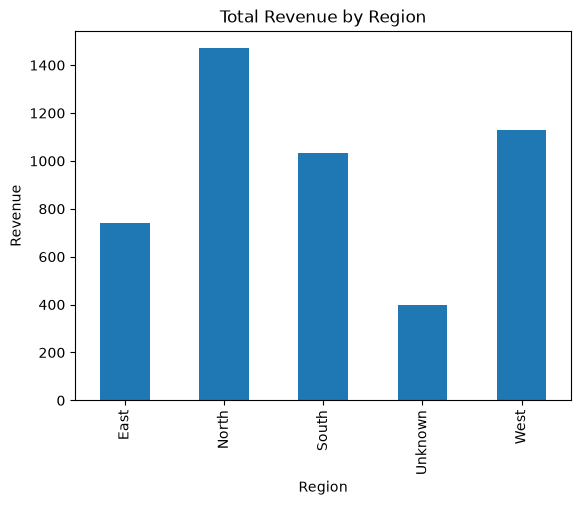

In [10]:
# Chart 1: Revenue by region
region_revenue.plot(kind="bar")
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

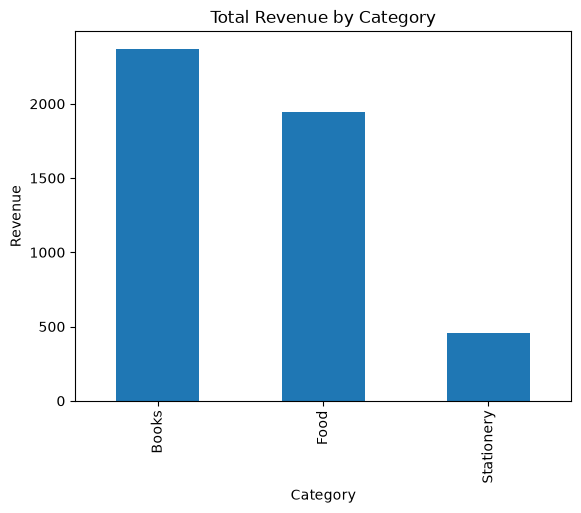

In [11]:
# Chart 2: Revenue by category
category_revenue.plot(kind="bar")
plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.show()

### Findings
1. **Books is the top category.** Books earned 2370 out of a total of 4775 revenue, which is about 50% of all sales. Stationery is the lowest with only 460 (about 10%).
2. **North is the top region.** North earned 1470, the highest among all regions, followed by West (1130) and South (1035). East is the lowest known region with 740. The `Unknown` group (400) is the sale whose region was missing.

## 4. Save the result

In [12]:
# Save the cleaned data to a new CSV (without the index column)
df.to_csv("cleaned_sales.csv", index=False)
print("cleaned_sales.csv saved")

cleaned_sales.csv saved


# Part B: CSV File Handling & Manipulation

## 1. Read and add a column

In [13]:
# Load the cleaned file from Part A
df2 = pd.read_csv("cleaned_sales.csv")

# Add tax_amount = 5% of revenue
df2["tax_amount"] = df2["revenue"] * 0.05

# Show first 5 rows
print(df2.head())

   transaction_id  sale_date region    category  quantity  unit_price  \
0            1001  10/1/2026  North        Food         2       120.0   
1            1002  10/1/2026  South       Books         1       250.0   
2            1003  10/2/2026  North        Food         3       110.0   
3            1004  10/2/2026   East  Stationery         4        50.0   
4            1005  10/3/2026  South       Books         2       250.0   

   revenue  tax_amount  
0    240.0        12.0  
1    250.0        12.5  
2    330.0        16.5  
3    200.0        10.0  
4    500.0        25.0  


## 2. Update and remove

In [14]:
# Increase unit_price of Books items by 10% using .loc[]
df2.loc[df2["category"] == "Books", "unit_price"] = df2.loc[df2["category"] == "Books", "unit_price"] * 1.10

# Recalculate revenue and tax_amount with the new prices
df2["revenue"] = df2["quantity"] * df2["unit_price"]
df2["tax_amount"] = df2["revenue"] * 0.05

# Check the Books rows
print(df2[df2["category"] == "Books"])

    transaction_id     sale_date   region category  quantity  unit_price  \
1             1002     10/1/2026    South    Books         1       275.0   
4             1005     10/3/2026    South    Books         2       275.0   
6             1008     10/4/2026     East    Books         1       330.0   
8             1012     10/6/2026    North    Books         1       352.0   
9             1014  invalid-date     West    Books         2       330.0   
12            1018     10/9/2026  Unknown    Books         2       220.0   

    revenue  tax_amount  
1     275.0       13.75  
4     550.0       27.50  
6     330.0       16.50  
8     352.0       17.60  
9     660.0       33.00  
12    440.0       22.00  


In [15]:
# Remove one row using an existing transaction_id (we remove 1002)
print("Rows before removing:", df2.shape[0])
df2 = df2[df2["transaction_id"] != 1002]
print("Rows after removing :", df2.shape[0])

Rows before removing: 15
Rows after removing : 14


In [16]:
# Create a temporary review_status column
df2["review_status"] = "Pending"
print(df2.columns)

# Remove it using drop(columns=...)
df2 = df2.drop(columns=["review_status"])
print(df2.columns)

Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price', 'revenue', 'tax_amount', 'review_status'],
      dtype='str')
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price', 'revenue', 'tax_amount'],
      dtype='str')


## 3. Save and verify

In [17]:
# Save to a new file
df2.to_csv("sales_updated.csv", index=False)

# Read it again to verify
check = pd.read_csv("sales_updated.csv")
print(check.head())

# Final column names
print(list(check.columns))

   transaction_id  sale_date region    category  quantity  unit_price  \
0            1001  10/1/2026  North        Food         2       120.0   
1            1003  10/2/2026  North        Food         3       110.0   
2            1004  10/2/2026   East  Stationery         4        50.0   
3            1005  10/3/2026  South       Books         2       275.0   
4            1007  10/4/2026  North  Stationery         3        60.0   

   revenue  tax_amount  
0    240.0        12.0  
1    330.0        16.5  
2    200.0        10.0  
3    550.0        27.5  
4    180.0         9.0  
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
